# Comparison with Energy and Wind

### horizontal kinetic energy

In [28]:
u_series = u[94.23][30:]
v_series = v[94.23][30:]
assert not np.any(u_series.isna())
assert not np.any(v_series.isna())

In [29]:
fs = 1 / (1 * 60 * 60)  # sampling period of 1 hour
cut = 1 / (13.8 * 60 * 60)  # tail end of the continuum
# cut = 1 / (7 * 60 * 60)  # tail end of the continuum
order = 40

sos = signal.butter(N=order, Wn=cut, btype="highpass", fs=fs, output="sos")
# use filtfilt with 2 filtering passes to prevent an artificial phase shift
superinertial_u = pd.Series(index=u_series.index, data=signal.sosfiltfilt(sos, u_series.values))
superinertial_v = pd.Series(index=v_series.index, data=signal.sosfiltfilt(sos, v_series.values))

(0.0008, 3)

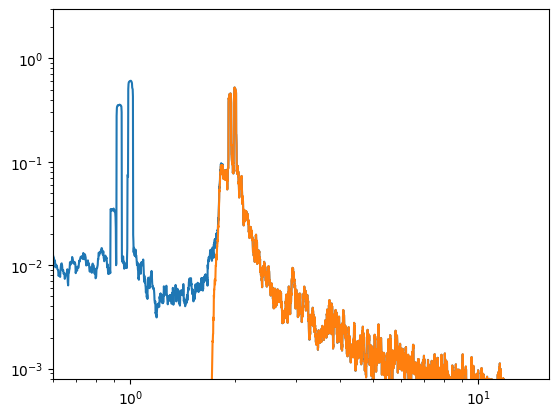

In [30]:
MEASUREMENT_PERIOD = 1 / 24
TIME_BANDWIDTH_PRODUCT = 10
freq, velocity_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    u_series.values, dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)
plt.loglog(freq, velocity_spectrum)
freq, velocity_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    superinertial_u.values, dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)
plt.loglog(freq, velocity_spectrum)
plt.gca().set_xlim(0.6, 16)
plt.gca().set_ylim(8e-4, 3)

<Axes: >

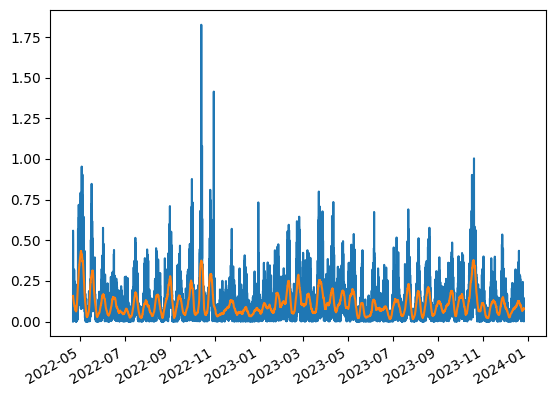

In [31]:
hke = 1 / 2 * (superinertial_u + 1j * superinertial_v).abs() ** 2
hke.plot()
smooth_hke = hke.rolling(window="5D", center=True).mean()
smooth_hke.plot()

In [32]:
hke

2022-04-21 21:09:47    0.000019
2022-04-21 22:09:47    0.558690
2022-04-21 23:09:47    0.143932
2022-04-22 00:09:47    0.533556
2022-04-22 01:09:47    0.470788
                         ...   
2023-12-26 11:09:47    0.047579
2023-12-26 12:09:47    0.041437
2023-12-26 13:09:47    0.019960
2023-12-26 14:09:47    0.074857
2023-12-26 15:09:47    0.002361
Length: 14731, dtype: float64

### Inertial Wind

In [33]:
inertial_wind = pd.read_csv(INTERIM_DATA_DIR / "inertial_wind_2022_2023.csv")
inertial_wind = inertial_wind.set_index(pd.to_datetime(inertial_wind["Unnamed: 0"]))
inertial_wind = inertial_wind.drop("Unnamed: 0", axis="columns")
for _i, col in enumerate(inertial_wind.columns):
    inertial_wind[col] = inertial_wind[col].str.replace("i", "j").apply(lambda x: complex(x))

# select mooring C and cut down to the length of the mesurement data
inertial_wind_at_C = inertial_wind["C"].loc[: hke.index[-1]]
# inertial_wind_at_C = inertial_wind_at_C

In [34]:
inertial_wind_at_C

Unnamed: 0
2022-01-01 00:00:00   -0.007281-0.017239j
2022-01-01 02:00:00    0.219972-0.162564j
2022-01-01 04:00:00    0.272507-0.146985j
2022-01-01 06:00:00    0.108214+0.016060j
2022-01-01 08:00:00   -0.142283+0.170167j
                              ...        
2023-12-26 06:00:00    0.465665+0.199695j
2023-12-26 08:00:00   -0.379530+0.222449j
2023-12-26 10:00:00   -0.893055+0.078409j
2023-12-26 12:00:00   -0.644205-0.099102j
2023-12-26 14:00:00    0.141273-0.173646j
Name: C, Length: 8696, dtype: complex128

In [35]:
smooth_wind = pd.Series(
    index=inertial_wind_at_C.index, data=smooth(inertial_wind_at_C.abs().to_numpy(), 30)
)

NameError: name 'smooth' is not defined

In [ ]:
fig, ax = plt.subplots(1, figsize=(8, 2), layout="constrained")

ax.set_ylabel("hke")  # \n$\\varepsilon_{\\mathrm{IGW}}\\,$(W$\\,$kg$^{-1}$)")

locator = mdates.AutoDateLocator(minticks=8, maxticks=12)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

(l_hke,) = ax.plot(
    smooth_hke.index,
    smooth_hke.to_numpy(),
    label="hke",  # $\\varepsilon_\\text{IGW}(t)$",
    lw=2,
)

ax2 = ax.twinx()
ax2.set_zorder(-1)
ax.set_facecolor("None")
(l_wind,) = ax2.plot(
    smooth_wind.index,
    smooth_wind.values,
    color="tab:red",
    label="inertial wind",
    lw=2,
)

ax2.set_ylabel("inertial wind / (m/s)$")

ax.legend(
    handles=[l_hke, l_wind],
    # title="measured at mooring C, 2350$\\,$m depth, 143$\\,$mab",
    ncol=1,
    fontsize=6,
    framealpha=0.9,
)

In [ ]:
#